Connected to isc (Python 3.11.10)

In [ ]:
from nilearn.image import math_img
from nilearn.plotting import plot_stat_map
import os
import seaborn as sns
from nilearn import plotting
from nilearn.plotting import view_img 

import time
import matplotlib.pyplot as plt
from importlib import reload
import nibabel as nib
import numpy as np
import pandas as pd
from nilearn.image import concat_imgs
from brainiak.isc import isc, bootstrap_isc, permutation_isc, compute_summary_statistic, phaseshift_isc
from nilearn.maskers import MultiNiftiMapsMasker, MultiNiftiMasker
from nilearn.datasets import fetch_atlas_schaefer_2018
from sklearn.utils import Bunch
from nilearn.plotting import view_img_on_surf
from nilearn.maskers import NiftiLabelsMasker
from nilearn.plotting import plot_glass_brain

from nilearn.plotting import find_parcellation_cut_coords

import src.isc_utils as isc_utils
import src.visu_utils as visu_utils
reload(visu_utils)
reload(isc_utils)

<module 'src.isc_utils' from '/data/rainville/dSutterlin/projects/ISC_hypnotic_suggestions/src/isc_utils.py'>

In [ ]:
model_names = {
    'model1_sugg_200': 'model1_sugg_23-sub_schafer-200-2mm_mask-whole-brain_pairWise-True_preproc_reg-mvmnt-True-8',
    'model1_sugg_run' : 'model1-runs_sugg_23-sub_schafer_tian-200-2mm_mask-whole-brain_pairWise-True_preproc_reg-mvmnt-True-8',
    'model1_sugg_200_run' : 'model1-ext-conds_sugg_23-sub_schafer-200-2mm_mask-whole-brain_pairWise-True_preproc_reg-mvmnt-True-8',
    'model1-6': 'model1_sugg_23-sub_schafer-200-2mm_mask-whole-brain_pairWise-True_preproc_reg-mvmnt-True-6',
    'model2_sugg_loo': 'model2_sugg_23-sub_schafer-200-2mm_mask-whole-brain_pairWise-False_preproc_reg-mvmnt-True-8',
    'model2_shock_loo': 'model2_shock_23-sub_schafer-200-2mm_mask-whole-brain_pairWise-False_preproc_reg-mvmnt-True-8',
    'model3_shock_200': 'model3_shock_23-sub_schafer-200-2mm_mask-whole-brain_pairWise-True_preproc_reg-mvmnt-True-8',
    'model3_shock_200_run' : 'model2-ext-conds_shock_23-sub_schafer-200-2mm_mask-whole-brain_pairWise-True_preproc_reg-mvmnt-True-8',
    'model1_mean': 'model4-mean_sugg_23-sub_schafer-200-2mm_mask-whole-brain_pairWise-True_preproc_reg-mvmnt-True-8',
    'model5_isfc_sugg' :'model5-isfc_sugg_23-sub_schafer-200-2mm_mask-lanA800_pairWise-True_preproc_reg-mvmnt-True-8',
    'model5_isfc_shock' : 'model5-isfc_shock_23-sub_schafer-200-2mm_mask-lanA800_pairWise-True_preproc_reg-mvmnt-True-8',
    '9 avril ...' : ' ',
    'single_trial_language_mask' : 'model_single-trial_sugg_23-sub_schafer-200-2mm_mask-lanA800_pairWise-True_preproc_reg-mvmnt-True-8',
    'single_trial_whole-brain' : 'model_single-trial-wb_sugg_23-sub_schafer-200-2mm_mask-whole-brain_pairWise-True_preproc_reg-mvmnt-True-8',
    'model5_sugg_tian' : 'model5-with-subcort_sugg_23-sub_schafer-200-2mm_mask-whole-brain_pairWise-True_preproc_reg-mvmnt-True-8',
    'model1_single-trial': 'model1_single-trial-wb_sugg_23-sub_schafer_tian-200-2mm_mask-whole-brain_pairWise-True_preproc_reg-mvmnt-True-8',
    'model2_sugg' : 'model2_sugg_23-sub_schafer_tian-200-2mm_mask-whole-brain_pairWise-True_preproc_reg-mvmnt-True-8',
    'model3_shock' : 'model3_shock_23-sub_schafer_tian-200-2mm_mask-whole-brain_pairWise-True_preproc_reg-mvmnt-True-8',
}

model_is = 'model3-shock'
model_is = 'model2_sugg-sensaas'
model_is = 'model5_sugg'
model_is = 'model1_single-trial'
model_is = 'model2_sugg'

# model_is = 'model3_shock_200'
# model_is = 'model1_sugg_200_run'
# model_is = 'model3_shock_200_run'
# model_is = 'model1_sugg_200'
# model_is = 'model1_sugg_run'


ref_preproc_models = { 'model2' : model_names['model1_sugg_200']}
ref_model_name = ref_preproc_models['model2']

project_dir = "/data/rainville/dSutterlin/projects/ISC_hypnotic_suggestions"

color_isc = 'Reds' 
# base_path = "/data/rainville/dSutterlin/projects/ISC_hypnotic_suggestions/results/data/test_data_sugg_3sub"
preproc_model_data = '23subjects_zscore_sample_detrend_FWHM6_low-pass428_10-12-24/suggestion_blocks_concat_4D_23sub'
base_path = os.path.join(project_dir, 'results/imaging/preproc_data', preproc_model_data)
model_name = model_names[model_is]
# preproc_model_name =  model_names['model1_sugg'] #'model3_shock_23-sub_schafer-200-2mm_mask-whole-brain_pairWise-True_preproc_reg-mvmnt-True-8'

results_dir = os.path.join(project_dir, f'results/imaging/ISC/{model_name}')
setup = isc_utils.load_json(os.path.join(results_dir, "setup_parameters.json"))

#create visualization dir.
save_visu = os.path.join(results_dir, 'post-hoc_VISU-tables')
os.makedirs(save_visu, exist_ok=True)

parcel_name = setup['atlas_name']
do_pairWise = setup['do_pairwise']
n_boot = setup['n_boot']

post_hoc_dir = os.path.join(results_dir, 'post_hoc_results')
os.makedirs(post_hoc_dir, exist_ok=True)

In [ ]:
# all_results_paths = utils.load_json(os.path.join(results_dir, "result_paths.json"))
# atlas_name = 'Difumo256' # change to setup['atlas_name']
# n_sub = setup['n_sub']
shaeffer_only = False
if shaeffer_only:

    atlas_data = fetch_atlas_schaefer_2018(n_rois = 200, resolution_mm=2)
    atlas = nib.load(atlas_data['maps'])
    atlas_path = atlas_data['maps'] #os.path.join(project_dir,os.path.join(project_dir, 'masks', 'k50_2mm', '*.nii*'))
    # labels_bytes = list(atlas_data['labels'])
    full_labels = [str(label, 'utf-8') if isinstance(label, bytes) else str(label) for label in atlas_data['labels']]
    roi_index = [full_labels.index(lbl)+1 for lbl in full_labels]
    id_labels_dct = dict(zip(roi_index, full_labels))

#---------------
#up to date scheaffer + subcortical regions
else:
    atlas = nib.load('/data/rainville/dSutterlin/projects/ISC_hypnotic_suggestions/masks/Tian2020_schaeffer200_subcortical16/combined_schaefer200_tian16_DSG.nii.gz')
    id_labels_dct = isc_utils.load_json('/data/rainville/dSutterlin/projects/ISC_hypnotic_suggestions/masks/Tian2020_schaeffer200_subcortical16/roi_labels_dict_DSG.json')
    #remove background 
    id_labels_dct.pop('0')
    full_labels = list(id_labels_dct.values())
    roi_index = list(id_labels_dct.keys())

atlas_masker = NiftiLabelsMasker(labels_img=atlas, labels=full_labels, standardize=False)
atlas_masker.fit()

# # Sensaas 
# # condition_target = ['all_sugg', 'A'
# atlas = nib.load('/data/rainville/dSutterlin/projects/ISC_hypnotic_suggestions/masks/sensaas/SENSAAS_MNI_ICBM_152_2mm.nii')
# atlas_data = pd.read_csv('/data/rainville/dSutterlin/projects/ISC_hypnotic_suggestions/masks/sensaas/SENSAAS_description.csv')
# # atlas = qc_utils.resamp_to_img_mask(atlas_native, ref_img)
# # view_img(atlas, threshold=0.5, title='SENSAAS atlas')
# #sensaas ids and labels
# roi_index = atlas_data['Index'].values
# atlas_data['annot_abbreviation'] = atlas_data['Abbreviation'] + '_' + atlas_data['Hemisphere']
# full_labels = atlas_data['annot_abbreviation'].values
# id_labels_dct = dict(zip(atlas_data['Index'], atlas_data['annot_abbreviation']))

if 'SENSAAS' in setup['atlas_name']:
    roi_coords = list(zip(
    atlas_data['Xmm'].astype(float),
    atlas_data['Ymm'].astype(float),
    atlas_data['Zmm'].astype(float)
    ))
else:
    roi_coords = find_parcellation_cut_coords(labels_img=atlas)

from nilearn import datasets, plotting
bg_mni =  datasets.load_mni152_template(resolution=1)

<ipython-input-3-9bcec7011657>:26: UserWarning: Mismatch between the number of provided labels (216) and the number of regions in provided label image (217).
  atlas_masker = NiftiLabelsMasker(labels_img=atlas, labels=full_labels, standardize=False)


[get_dataset_dir] Dataset found in /home/dsutterlin/nilearn_data/fsaverage6

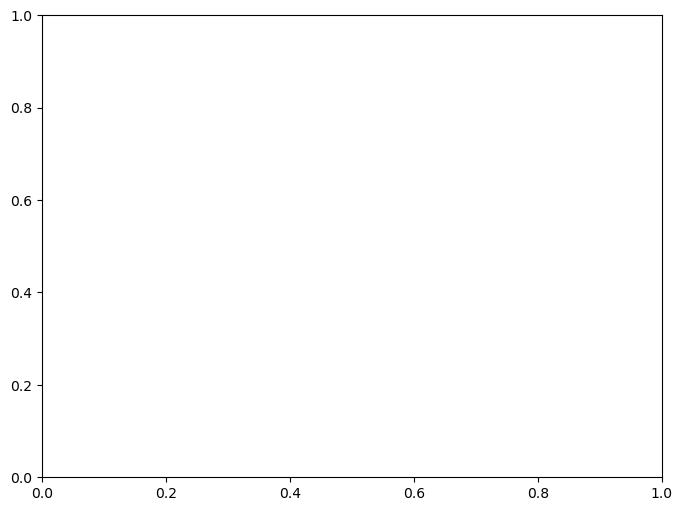

In [ ]:
from nilearn.plotting import plot_roi
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from nibabel.freesurfer import read_annot
from nilearn import datasets, plotting, surface

base_cmap = plt.get_cmap('tab20')
colors = base_cmap.colors * 11  # Repeat to cover 220+ parcels
colors = np.array(colors)

# plot_roi(atlas, bg_img =bg_mni, title='SENSAAS Atlas', display_mode = 'x', cut_coords = [0, -40, 45,48, 50,55, 60], view_type = 'continuous', colorbar=True, cmap=custom_cmap, linewidths=3)
shuffle_idx = np.argsort(np.sin(np.linspace(0, np.pi, len(colors))))  # or use np.random.permutation for random
shuffled_colors = colors[shuffle_idx]
shuffled_cmap = ListedColormap(shuffled_colors)

# Use fsaverage surface
fsaverage = datasets.fetch_surf_fsaverage(mesh='fsaverage6')
# Downloaded from shaeffer github repo
annot_path = '/home/dsutterlin/Downloads/rh.Schaefer2018_200Parcels_7Networks_order.annot'

# Load as GIFTI label texture
labels, ctab, names = read_annot(annot_path)

fig = plt.figure(figsize=(8, 6))
ax = plt.gca()

# Plot the surface atlas using Nilearn
im = plotting.plot_surf_stat_map(
    fsaverage.infl_right,
    stat_map=labels,
    hemi='right',
    bg_on_data=True,
    alpha=0.9,
    colorbar=False,
    title= None,
    cmap=shuffled_cmap,
    output_file = os.path.join(post_hoc_dir, "schaefer200_surface.png")
)

In [ ]:
from src import preproc_utils

isc_results_roi = {}

behav_df = pd.read_csv(
    os.path.join(setup['project_dir'], f'results/behavioral_data_cleaned.csv'),
    index_col=0
)
behav_df.index.name = 'subjects'
behav_df = behav_df.sort_index()

xlsx_path = r'/data/rainville/dSutterlin/projects/ISC_hypnotic_suggestions/masks/Hypnosis_variables_20190114_pr_jc.xlsx'
subjects = list(setup['subjects'])
apm_subjects = ['APM' + subj[4:] for subj in subjects]
Y = preproc_utils.load_process_y(xlsx_path, subjects)

/data/rainville/dSutterlin/projects/ISC_hypnotic_suggestions/src/preproc_utils.py:78: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  filledY = cutY.fillna(cutY.astype(float).mean()).astype(float)


In [ ]:
# Bootstrap per condition visualization
# =====================================
reload(visu_utils)
reload(isc_utils)
result_key = 'isc_results'
conditions = ['NANA', 'ANA', 'NHYPER', 'HYPER'] if 'single-trial' not in model_name else ['N_ANA1_instrbk_1', 'N_HYPER1_instrbk_1']
all_conditions = setup['conditions'] + setup['combined_conditions'] #['HYPER', 'ANA', 'NANA', 'NHYPER']
conditions = setup['conditions']

----------------------------------------------------
HYPER
FDR thresh : 0.00019998000199980003
Max ISC value: 0.06620566603936569
Sig ROIs : ['7Networks_LH_Default_Temp_3']
----------------------------------------------------
ANA
FDR thresh : 0.004299570042995701
Max ISC value: 0.22035720488095958
Sig ROIs : ['7Networks_LH_SomMot_1', '7Networks_LH_SomMot_2', '7Networks_LH_SomMot_15', '7Networks_LH_SalVentAttn_Med_1', '7Networks_LH_Default_Temp_3', '7Networks_LH_Default_Temp_5', '7Networks_RH_Vis_6', '7Networks_RH_SomMot_1', '7Networks_RH_SomMot_2', '7Networks_RH_Default_Temp_3', '7Networks_RH_Default_Temp_4', '7Networks_RH_Default_Temp_5']
----------------------------------------------------
NHYPER
FDR thresh : 0.0008999100089991
Max ISC value: 0.0923417814739563
Sig ROIs : ['7Networks_LH_Default_Temp_3', '7Networks_RH_Vis_6', '7Networks_RH_SomMot_1', '7Networks_RH_Default_Temp_3']
----------------------------------------------------
NANA
FDR thresh : 0.015498450154984501
Max ISC value

/home/dsutterlin/miniconda3/envs/isc/lib/python3.11/site-packages/nilearn/plotting/displays/_slicers.py:313: UserWarning: empty mask
  ims = self._map_show(img, type="imshow", threshold=threshold, **kwargs)


Sig ROIs : []
----------------------------------------------------
ANA
FDR thresh : 0.004299570042995701
Max ISC value: 0.22035720488095958
Sig ROIs : ['7Networks_LH_SomMot_1', '7Networks_LH_SomMot_2', '7Networks_LH_SomMot_7', '7Networks_LH_SomMot_15', '7Networks_LH_SalVentAttn_ParOper_3', '7Networks_LH_SalVentAttn_Med_1', '7Networks_LH_Limbic_TempPole_1', '7Networks_LH_Default_Temp_1', '7Networks_LH_Default_Temp_3', '7Networks_LH_Default_Temp_5', '7Networks_RH_Vis_6', '7Networks_RH_SomMot_1', '7Networks_RH_SomMot_2', '7Networks_RH_SomMot_18', '7Networks_RH_SalVentAttn_TempOccPar_1', '7Networks_RH_Cont_Cing_2', '7Networks_RH_Default_Temp_2', '7Networks_RH_Default_Temp_3', '7Networks_RH_Default_Temp_4', '7Networks_RH_Default_Temp_5']
----------------------------------------------------
NHYPER
FDR thresh : 0.0008999100089991
Max ISC value: 0.0923417814739563
Sig ROIs : ['7Networks_LH_Default_Temp_3', '7Networks_RH_SomMot_1', '7Networks_RH_Default_Temp_3']
--------------------------------

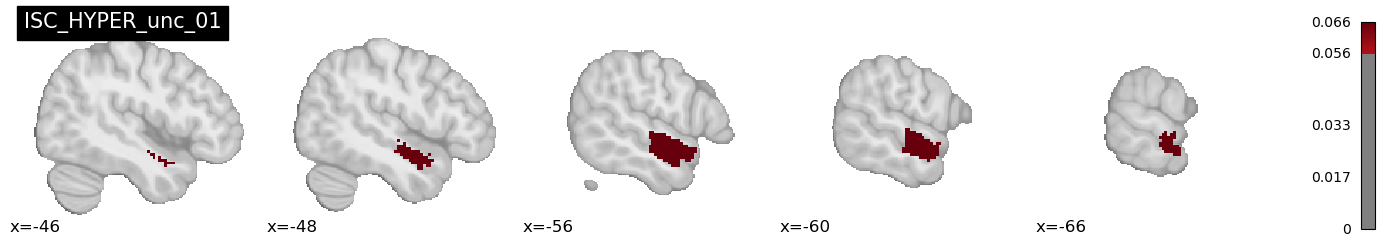

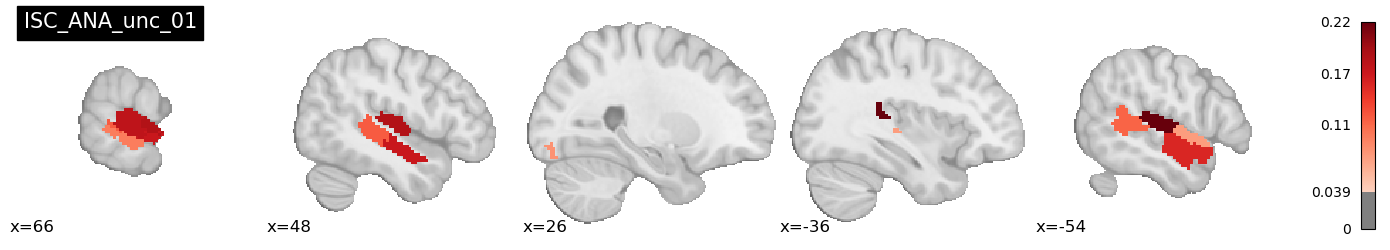

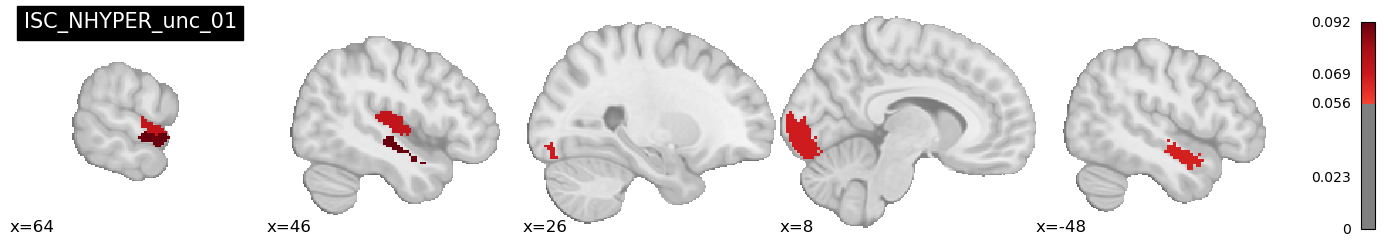

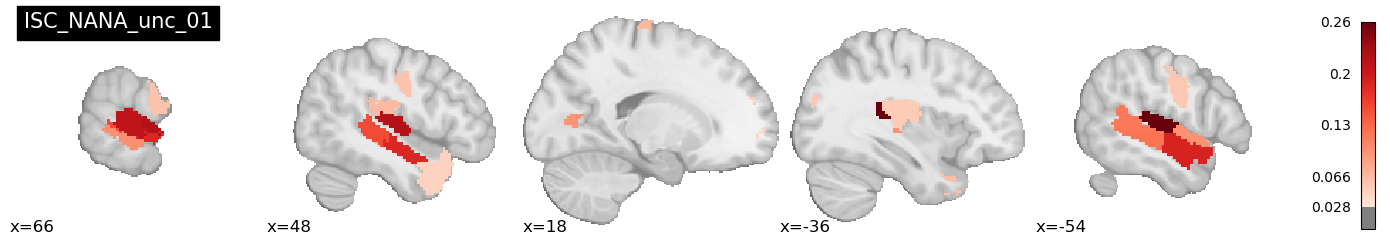

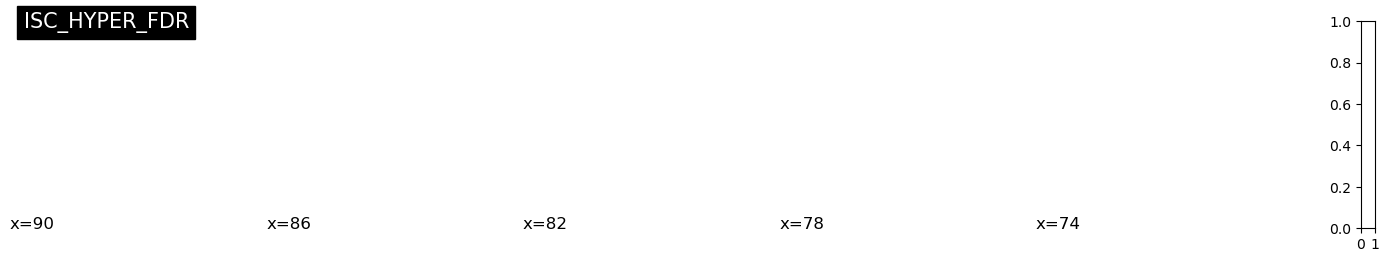

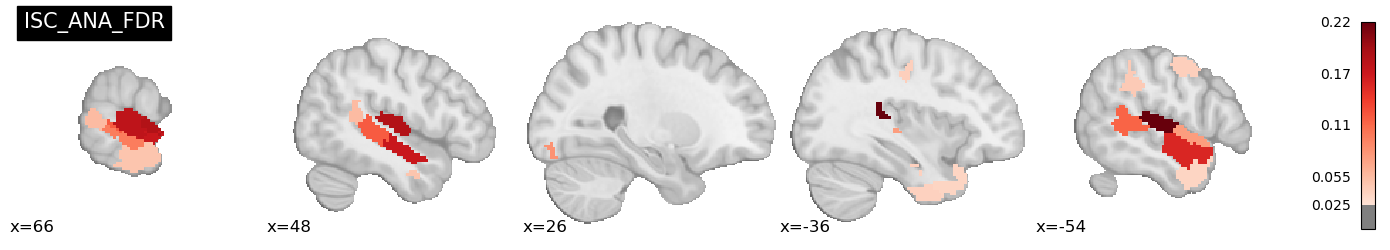

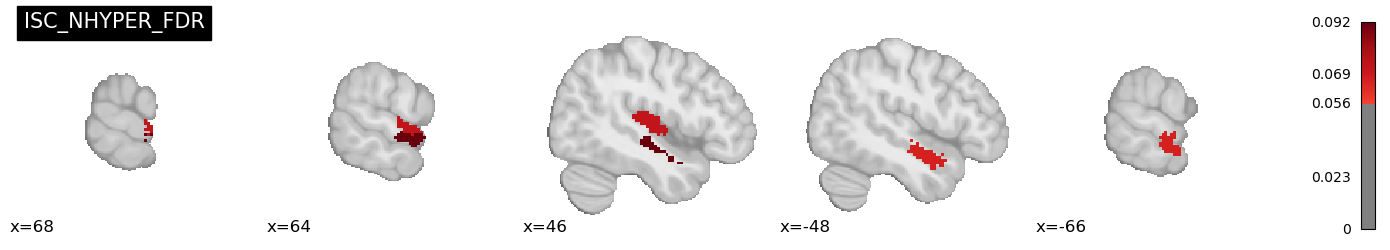

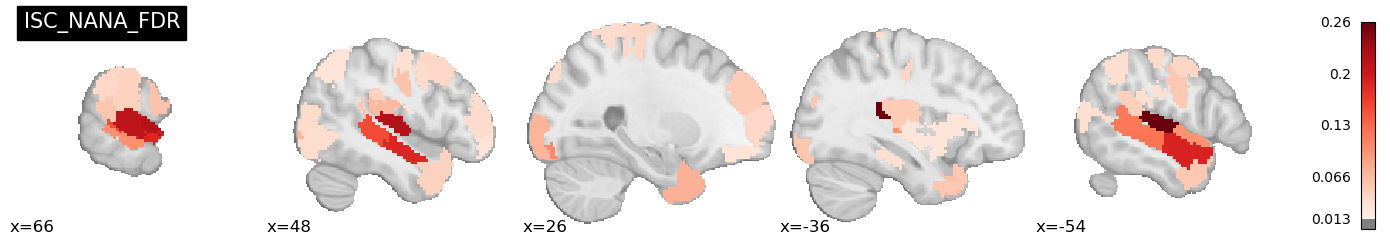

In [ ]:
reload(visu_utils)

iscs_cond = {}
isc_p_cond = {}
isc_imgs = {} #used further to produce brain plots of each conditions
views = {}
surf = {}
interactive_views = []
sig_dfs_one_sample = {}

save_plots_1sample = os.path.join(save_visu, 'plots_1sample_isc')
os.makedirs(save_plots_1sample, exist_ok=True)
save_tables_1sample = os.path.join(save_visu, 'tables_1sample_isc')
os.makedirs(save_tables_1sample, exist_ok=True)

for correction in ['unc_01', 'FDR']: #VAriables are stored for FDR
    # Generate stats tables for each conditions and save
    for cond in setup['conditions']: #'NHYPER']: #conditions:
        print('----------------------------------------------------')
        print(cond)

        maskers = isc_utils.load_pickle(f'/data/rainville/dSutterlin/projects/ISC_hypnotic_suggestions/results/imaging/ISC/{model_name}/{cond}/maskers_{parcel_name}_{cond}_23sub.pkl')
        atlas = maskers[0].labels_img # adjust number of ROI based on mask
        labels = list(maskers[0].region_names_.values())
        if labels == None:
            labels = [f'ROI_{i}' for i in range(isc_rois.shape[1])]

        # accounts for a case where we masked the brain, e.g. with LAN800
        #labels are ok, but need index to access proper coords
        if len(labels) != len(full_labels):
            labels_indices = [full_labels.index(lbl) for lbl in labels]
            print(labels_indices)
        else:
            labels_indices = list(range(len(labels)))
            # used for coords 
        
        isc_bootstrap = isc_utils.load_pickle(os.path.join(project_dir, f'results/imaging/ISC/{model_name}/{cond}/isc_results_{cond}_{n_boot}boot_pairWise{do_pairWise}.pkl'))
        isc_rois = pd.DataFrame(isc_bootstrap['isc'], columns=labels)
        isc_results_roi[cond] = isc_rois
        isc_median = isc_bootstrap['observed']
        # print(isc_median, np.mean(isc_rois))
        ci = isc_bootstrap['confidence_intervals']
        p_values = isc_bootstrap['p_values']
        dist = isc_bootstrap['distribution']
        n_boot = setup['n_boot']
        
        iscs_cond[cond] = isc_median
        isc_p_cond[cond] = p_values
        if correction == 'unc_01':
            fdr_p = 0.001
        elif correction == 'FDR':
            fdr_p = isc_utils.fdr(p_values, q=0.05)

        bonf_p = isc_utils.bonferroni(p_values, alpha=0.05)
        print(f'FDR thresh : {isc_utils.fdr(p_values, q=0.05)}')
        
        title_view = f'ISC_{cond}_{correction}'
        file_id = f'ISC_{cond}_FDR05'

        #x = -48, -2, 6, 50
        cut_coords = (5) #(-48, -2, 6, 50)
        isc_img, isc_thresh, sig_df = visu_utils.project_isc_to_brain(
            atlas_img=atlas,
            isc_median=isc_median,
            atlas_labels=id_labels_dct,
            roi_coords = roi_coords,
            p_values=p_values,
            p_threshold=fdr_p, #modif in loop
            title = title_view,
            coords_bool_mask = labels_indices,
            save_path=None,
            show=True,
            display_mode='x',
            cut_coords_plot=cut_coords,
        )

        isc_imgs[cond] = (isc_img, isc_thresh)
        p_mask = p_values < fdr_p
        sig_labels = [labels[i] for i in range(len(labels)) if p_mask[i]]
        sig_dfs_one_sample[cond] = sig_df #sig_df.sort_values(by='ISC', ascending=False)
        print('Sig ROIs :', sig_labels)
        
        #save sign dfs as csv
        if sig_df.shape[0] > 0:
            # sig_labels = pd.DataFrame(sig_labels, columns=['ROI', 'Label', 'spearman_r', 'p_values', 'Coordinates (X,Y,Z)'])
            sig_df.columns = ['Region id', 'Label', 'ISC', 'P-value', 'Coordinates (X,Y,Z)']
            sig_df.to_csv(os.path.join(save_tables_1sample, f'ISC_{cond}_table_{correction}_thresh{round(fdr_p,4)}.csv'), index=False)

FDR across all conditions :  0.0036996300369963003
Max ISC value: 0.06620566603936569
Sig ROIs : ['7Networks_LH_Default_Temp_3', '7Networks_RH_Default_Temp_3']
Max ISC value: 0.22035720488095958
Sig ROIs : ['7Networks_LH_SomMot_1', '7Networks_LH_SomMot_2', '7Networks_LH_SomMot_7', '7Networks_LH_SomMot_15', '7Networks_LH_SalVentAttn_ParOper_3', '7Networks_LH_SalVentAttn_Med_1', '7Networks_LH_Limbic_TempPole_1', '7Networks_LH_Default_Temp_3', '7Networks_LH_Default_Temp_5', '7Networks_RH_Vis_6', '7Networks_RH_SomMot_1', '7Networks_RH_SomMot_2', '7Networks_RH_SomMot_18', '7Networks_RH_SalVentAttn_TempOccPar_1', '7Networks_RH_Cont_Cing_2', '7Networks_RH_Default_Temp_2', '7Networks_RH_Default_Temp_3', '7Networks_RH_Default_Temp_4', '7Networks_RH_Default_Temp_5']
Max ISC value: 0.0923417814739563
Sig ROIs : ['7Networks_LH_SomMot_2', '7Networks_LH_Default_Temp_3', '7Networks_LH_Default_Temp_5', '7Networks_RH_Vis_6', '7Networks_RH_SomMot_1', '7Networks_RH_Default_Temp_3']
Max ISC value: 0.26435

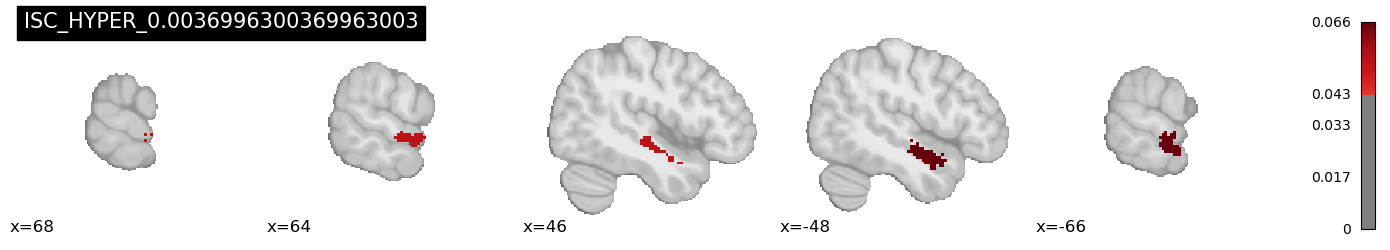

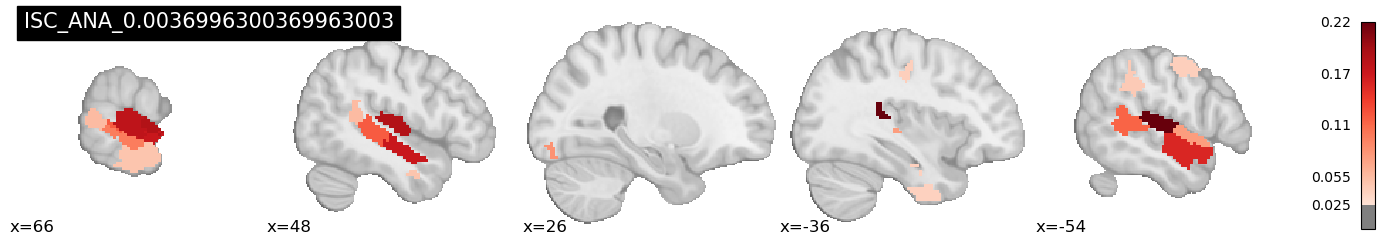

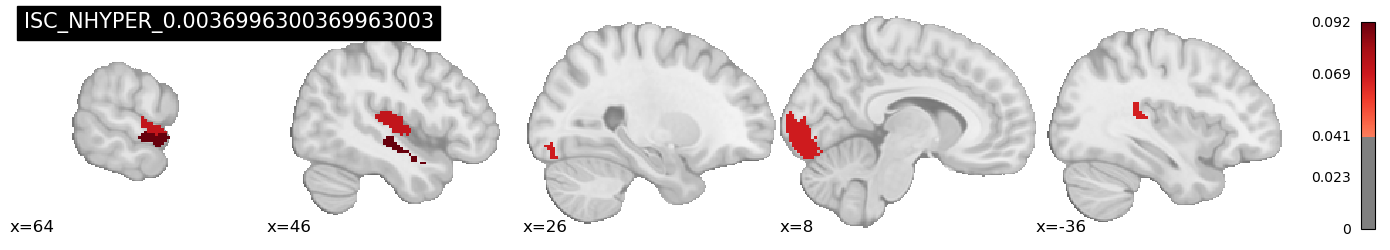

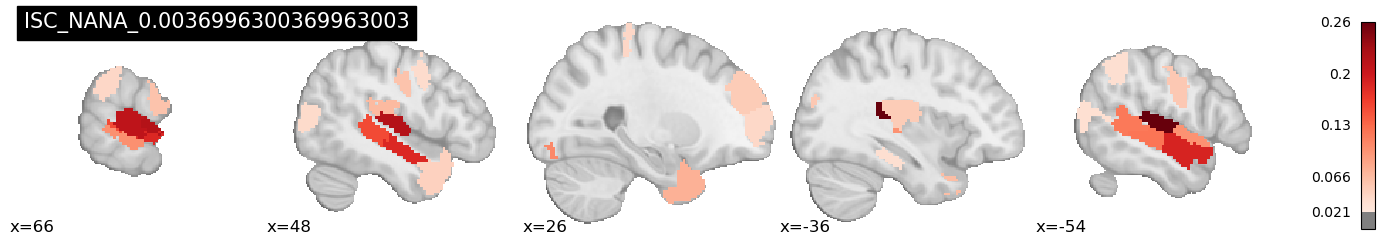

In [ ]:
# FDR thresh across all conditions
all_ps = []
for cond in setup['conditions']:
    p = isc_p_cond[cond]
    all_ps.extend(p)
fdr_all = isc_utils.fdr(np.array(all_ps), q=0.05)
print('FDR across all conditions : ', fdr_all)

# Re-comute with this threshold
correction = fdr_all
for cond in setup['conditions']:

        isc_bootstrap = isc_utils.load_pickle(os.path.join(project_dir, f'results/imaging/ISC/{model_name}/{cond}/isc_results_{cond}_{n_boot}boot_pairWise{do_pairWise}.pkl'))
        isc_rois = pd.DataFrame(isc_bootstrap['isc'], columns=labels)
        isc_median = isc_bootstrap['observed']
        p_values = isc_bootstrap['p_values']
        dist = isc_bootstrap['distribution']
        
        title_view = f'ISC_{cond}_{correction}'

        #x = -48, -2, 6, 50
        cut_coords = (5) #(-48, -2, 6, 50)
        isc_img, isc_thresh, sig_df = visu_utils.project_isc_to_brain(
            atlas_img=atlas,
            isc_median=isc_median,
            atlas_labels=id_labels_dct,
            roi_coords = roi_coords,
            p_values=p_values,
            p_threshold=correction, #modif in loop
            title = title_view,
            coords_bool_mask = labels_indices,
            save_path=None,
            show=True,
            display_mode='x',
            cut_coords_plot=cut_coords,
        )
        global_fdr_img = (isc_img, isc_thresh)
        p_mask = p_values < correction
        sig_labels = [labels[i] for i in range(len(labels)) if p_mask[i]]
        sig_dfs_one_sample[cond] = sig_df #sig_df.sort_values(by='ISC', ascending=False)
        print('Sig ROIs :', sig_labels)

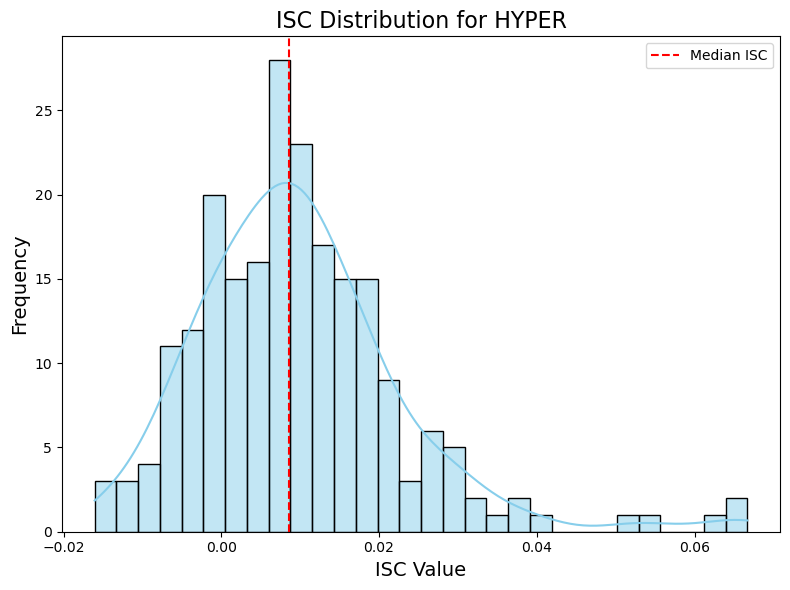

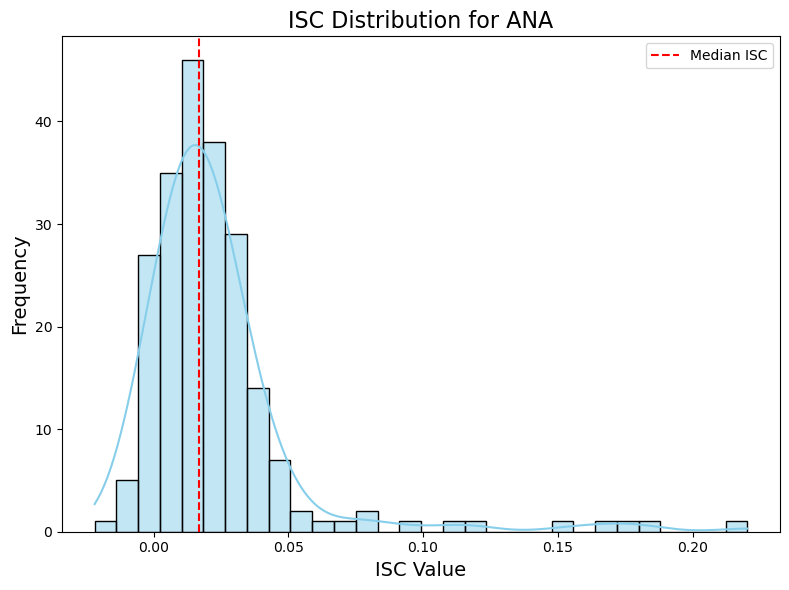

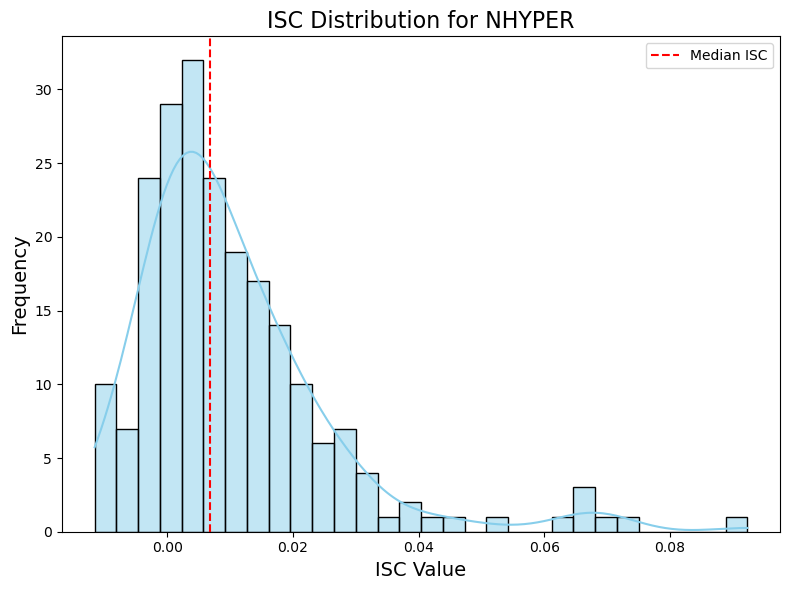

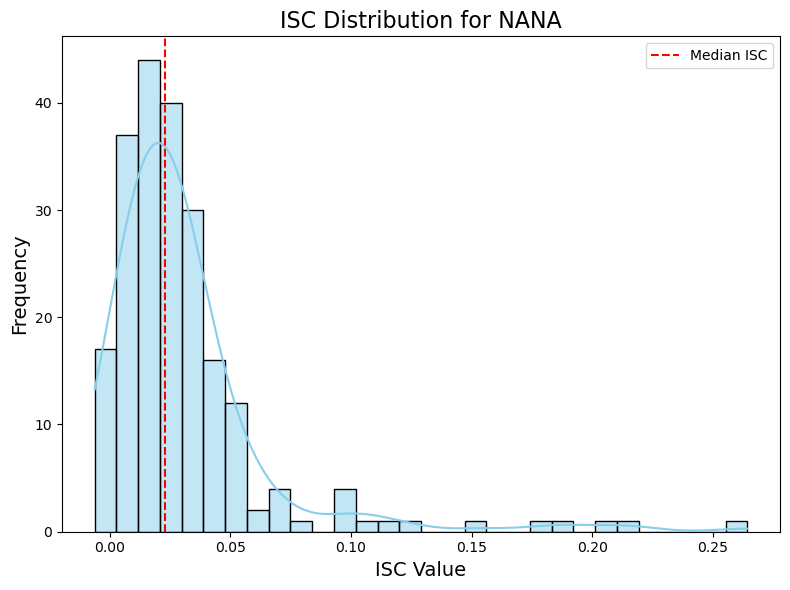

In [ ]:
for cond in setup['conditions']:
    isc_values = iscs_cond[cond]
    p_values = isc_p_cond[cond]
    # histogram 
    plt.figure(figsize=(8, 6))
    sns.histplot(isc_values, bins=30, kde=True, color='skyblue')
    plt.title(f'ISC Distribution for {cond}', fontsize=16)
    plt.xlabel('ISC Value', fontsize=14)
    plt.ylabel('Frequency', fontsize=14)
    plt.axvline(np.median(isc_values), color='red', linestyle='--', label='Median ISC')
    plt.legend()
    plt.tight_layout()
    # plt.savefig(os.path.join(save_plots_1sample, f'ISC_distribution_{cond}.png'), dpi=300)

NameError: name 'isc_values_cond' is not defined

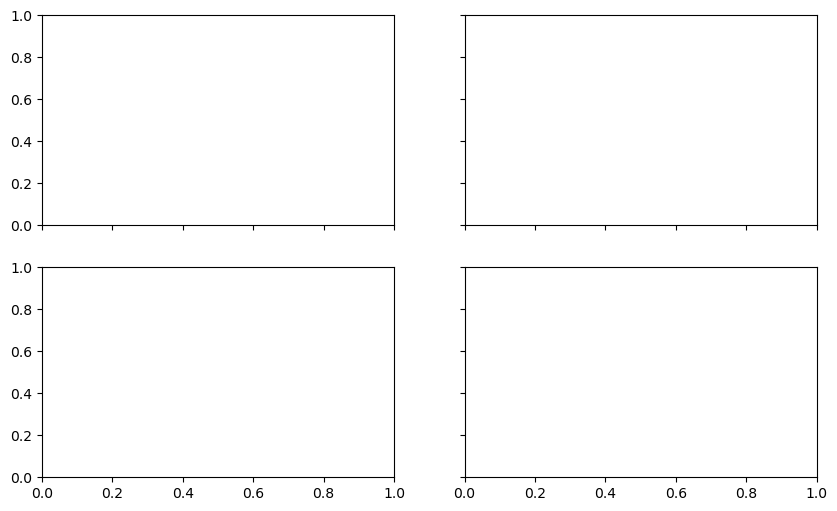

In [ ]:
for cond in setup['conditions']:
    isc_values = iscs_cond[cond]
    p_values = isc_p_cond[cond]
    # histogram with distribution on the same plot. Use the same scale for all conditions
    # Add a lengend witht a distribution per conditions
    # Add each condition median in a vertical line with similar color as the distribution
from scipy.stats import gaussian_kde

fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True, sharey=True)
axes = axes.flatten()

x_vals = np.linspace(-0.2, 0.5, 500)

for ax, cond in zip(axes, conditions):
    values = isc_values_cond[cond]
    kde = gaussian_kde(values)
    ax.plot(x_vals, kde(x_vals), color=colors[cond], label=cond)
    ax.fill_between(x_vals, kde(x_vals), alpha=0.3, color=colors[cond])
    median_val = np.median(values)
    ax.axvline(median_val, color=colors[cond], linestyle='--')
    ax.set_title(cond)
    ax.set_xlabel('ISC')
    ax.set_ylabel('Density')

# Global legend
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=4)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

IndexError: only integers, slices (`:`), ellipsis (`...`), numpy.newaxis (`None`) and integer or boolean arrays are valid indices

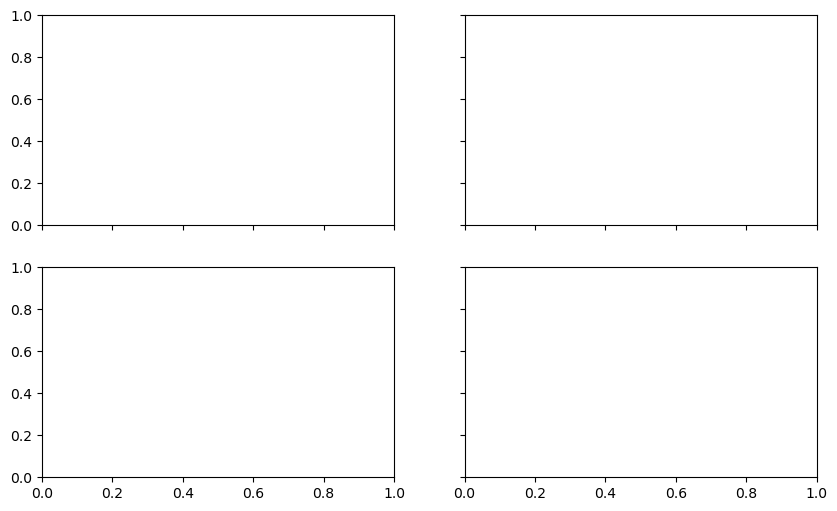

In [ ]:
for cond in setup['conditions']:
    isc_values = iscs_cond[cond]
    p_values = isc_p_cond[cond]
    # histogram with distribution on the same plot. Use the same scale for all conditions
    # Add a lengend witht a distribution per conditions
    # Add each condition median in a vertical line with similar color as the distribution
from scipy.stats import gaussian_kde

fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True, sharey=True)
axes = axes.flatten()

x_vals = np.linspace(-0.2, 0.5, 500)

for ax, cond in zip(axes, conditions):
    values = iscs_cond[cond]
    kde = gaussian_kde(values)
    ax.plot(x_vals, kde(x_vals), color=colors[cond], label=cond)
    ax.fill_between(x_vals, kde(x_vals), alpha=0.3, color=colors[cond])
    median_val = np.median(values)
    ax.axvline(median_val, color=colors[cond], linestyle='--')
    ax.set_title(cond)
    ax.set_xlabel('ISC')
    ax.set_ylabel('Density')

# Global legend
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=4)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

IndexError: only integers, slices (`:`), ellipsis (`...`), numpy.newaxis (`None`) and integer or boolean arrays are valid indices

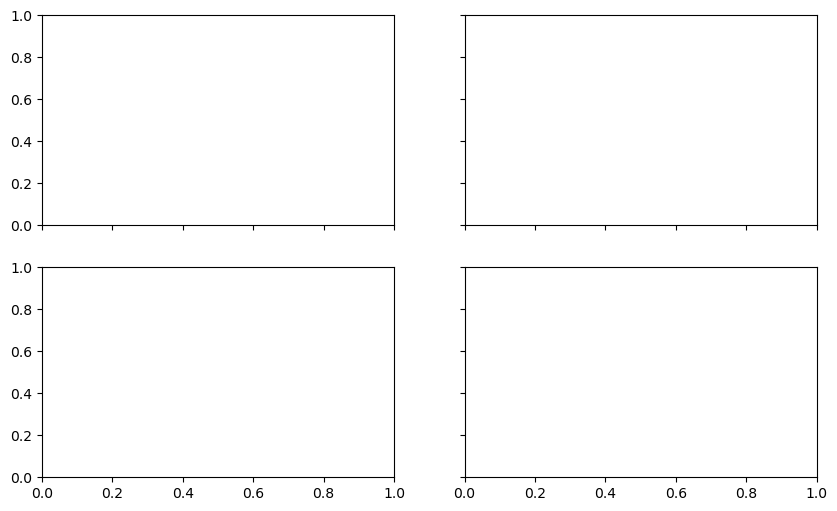

In [ ]:
for cond in setup['conditions']:
    isc_values = iscs_cond[cond]
    p_values = isc_p_cond[cond]
    # histogram with distribution on the same plot. Use the same scale for all conditions
    # Add a lengend witht a distribution per conditions
    # Add each condition median in a vertical line with similar color as the distribution
from scipy.stats import gaussian_kde

fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True, sharey=True)
axes = axes.flatten()

x_vals = np.linspace(-0.2, 0.5, 500)

for ax, cond in zip(axes, conditions):
    values = iscs_cond[cond].astype(float)
    kde = gaussian_kde(values)
    ax.plot(x_vals, kde(x_vals), color=colors[cond], label=cond)
    ax.fill_between(x_vals, kde(x_vals), alpha=0.3, color=colors[cond])
    median_val = np.median(values)
    ax.axvline(median_val, color=colors[cond], linestyle='--')
    ax.set_title(cond)
    ax.set_xlabel('ISC')
    ax.set_ylabel('Density')

# Global legend
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=4)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()